# EGFR inhibitors in ChEMBL: potency, data quality and resistance mutations

**Module 02.1 · my implementation** — Seid Adem

The **epidermal growth factor receptor (EGFR)** is a receptor tyrosine kinase and a major drug target in non-small-cell
lung cancer (NSCLC). Activating mutations (e.g. **L858R**) make tumours sensitive to EGFR inhibitors, but tumours escape:
the **T790M** "gatekeeper" mutation causes resistance to first-generation drugs, and **C797S** to the covalent
third-generation drug osimertinib. This is why EGFR drugs come in generations.

This notebook retrieves every EGFR **IC50** measurement with a standardised potency value from **ChEMBL** and asks:

1. How much does cleaning change the dataset?
2. How potent are published EGFR inhibitors?
3. How reproducible is a potency value across assays and assay types?
4. Do the approved drugs show the expected resistance pattern on mutant EGFR?
5. Which compounds are selective for the resistant mutant over wild type?
6. How has published EGFR chemistry changed over time?

**Potency scale:** pIC50 = −log10(IC50 in mol/L). pIC50 6 = 1 µM, **7 = 100 nM**, 8 = 10 nM, 9 = 1 nM. One unit = 10× more potent.

Tools: my client [`dsls.ebi_api`](../../../src/dsls/ebi_api.py) and the curation functions in
[`dsls.chembl`](../../../src/dsls/chembl.py) (unit-tested in [`tests/test_chembl.py`](../../../tests/test_chembl.py)).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from dsls.chembl import ACTIVITY_FIELDS, aggregate, curate, has_mutation
from dsls.ebi_api import REPO_ROOT, chembl

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
PROCESSED = REPO_ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
TARGET = "CHEMBL203"  # Epidermal growth factor receptor erbB1, Homo sapiens

## 1 · Retrieve the data

ChEMBL's API returns errors for deep offsets (in testing, page 11 of a single 19k-record query failed repeatedly), so the
query is split into **publication-year slices**, each under 10,000 records. Every page is cached in
`data/raw/api_cache/chembl/`, so re-running is offline and identical. The assertion checks that the slices add up to
ChEMBL's own total, so nothing was lost or double-counted.

In [2]:
client = chembl("activities", timeout=240, max_retries=8)
status = client.get_json("chembl/api/data/status.json")
target = client.get_json(f"chembl/api/data/target/{TARGET}.json")

BASE = {"target_chembl_id": TARGET, "standard_type": "IC50", "pchembl_value__isnull": "false"}
PARTS = {
    "<2008": {"document_year__lt": 2008},
    "2008-2012": {"document_year__gte": 2008, "document_year__lt": 2013},
    "2013-2016": {"document_year__gte": 2013, "document_year__lt": 2017},
    "2017-2020": {"document_year__gte": 2017, "document_year__lt": 2021},
    ">=2021": {"document_year__gte": 2021},
    "no year": {"document_year__isnull": "true"},
}
total = client.get_json("chembl/api/data/activity.json", {**BASE, "limit": 1})["page_meta"]["total_count"]

records = []
for p in PARTS.values():
    records += client.paginate_items(
        "chembl/api/data/activity.json",
        {**BASE, **p, "only": ACTIVITY_FIELDS, "limit": 1000, "order_by": "activity_id"},
    )
raw = pd.DataFrame(records)
assert len(raw) == total and raw["activity_id"].is_unique, "partitions don't add up to ChEMBL's total"

pd.Series(
    {
        "target": f"{target['pref_name']} ({target['organism']}, {TARGET})",
        "ChEMBL release": status["chembl_db_version"],
        "IC50 records with pChEMBL": total,
        "distinct compounds": raw["parent_molecule_chembl_id"].nunique(),
        "source documents": raw["document_chembl_id"].nunique(),
    },
    name="value",
).to_frame()

,value
target,Epidermal growth factor receptor (Homo sapiens...
ChEMBL release,ChEMBL_37
IC50 records with pChEMBL,19378
distinct compounds,10687
source documents,1041


## 2 · Q1 — How much does cleaning change the dataset?

Three explicit filters (see [`curate`](../../../src/dsls/chembl.py)): exact values only; no ChEMBL data-validity flag;
no potential duplicates (values re-reported from an earlier paper). Then repeated measurements of the same compound are
collapsed to a **median**, separately for each EGFR variant and assay kind.

In [3]:
clean, funnel = curate(raw)
clean.to_csv(PROCESSED / "chembl_egfr_ic50_clean.csv", index=False)
funnel

,step,records,removed
0,retrieved,19378,0
1,exact value with pChEMBL,19378,0
2,no data-validity flag,19378,0
3,not a potential duplicate,17272,2106


In [4]:
per_compound = aggregate(clean)
print(
    f"{len(clean):,} measurements → {len(per_compound):,} compound × variant × assay-kind values "
    f"({clean['parent_molecule_chembl_id'].nunique():,} compounds)"
)
pd.crosstab(clean["assay_kind"], clean["variant"] == "WT", margins=True).rename(
    columns={True: "wild type", False: "mutant"}
)

17,272 measurements → 13,441 compound × variant × assay-kind values (10,687 compounds)


variant,mutant,wild type,All
assay_kind,,,
biochemical,3813,12288,16101
cell-based,0,683,683
other,0,488,488
All,3813,13459,17272


In [5]:
variant_counts = (
    clean.groupby("variant")
    .agg(measurements=("pIC50", "size"), compounds=("parent_molecule_chembl_id", "nunique"))
    .sort_values("measurements", ascending=False)
)
mutant = clean[~clean["variant"].isin(["WT", "undefined mutant"])]
for m in ("L858R", "T790M", "C797S"):
    print(
        f"{m}: in {mutant['variant'].map(lambda v, m=m: has_mutation(v, m)).mean():.0%} of mutant measurements"
    )
variant_counts.head(12)

L858R: in 89% of mutant measurements
T790M: in 75% of mutant measurements
C797S: in 20% of mutant measurements


,measurements,compounds
variant,,
WT,13459,9904
T790M/L858R,1496,1310
undefined mutant,720,483
L858R,680,613
T790M/C797S/L858R,550,463
T790M,223,213
L861Q,44,42
C797S/L858R,42,42
T790M/L858M,29,29


**Note on `undefined mutant`:** ChEMBL's variant field records point mutations only. Assays on other alterations,
including the **exon 20 insertions** that mobocertinib targets (e.g. D770_N771insSVD), are labelled
"UNDEFINED MUTATION", and the actual mutation is only in the free-text assay description. These are kept separate
and are not counted as a known mutant.

## 3 · Q2 — How potent are published EGFR inhibitors?

Wild-type EGFR, biochemical assays, one median value per compound.

,share of compounds
≤ 1 µM (pIC50 ≥ 6),73%
≤ 100 nM (≥ 7),49%
≤ 10 nM (≥ 8),24%
≤ 1 nM (≥ 9),5%


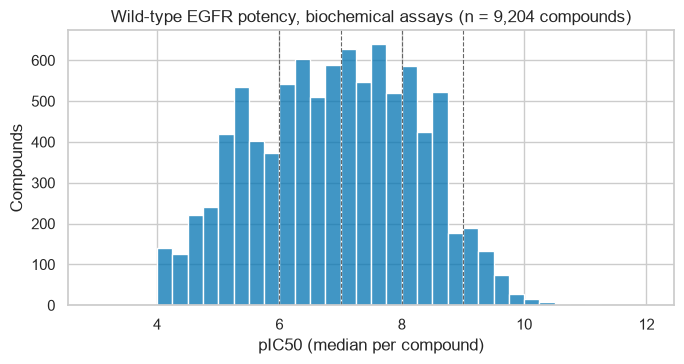

In [6]:
wt_bio = per_compound.query("variant == 'WT' and assay_kind == 'biochemical'")
thresholds = {"≤ 1 µM (pIC50 ≥ 6)": 6, "≤ 100 nM (≥ 7)": 7, "≤ 10 nM (≥ 8)": 8, "≤ 1 nM (≥ 9)": 9}
share = pd.Series(
    {k: (wt_bio["pIC50_median"] >= v).mean() for k, v in thresholds.items()}, name="share of compounds"
)

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.histplot(
    wt_bio["pIC50_median"], bins=np.arange(3, 12.01, 0.25), color=sns.color_palette("colorblind")[0], ax=ax
)
for v in (6, 7, 8, 9):
    ax.axvline(v, color="0.4", lw=0.8, ls="--")
ax.set(
    xlabel="pIC50 (median per compound)",
    ylabel="Compounds",
    title=f"Wild-type EGFR potency, biochemical assays (n = {len(wt_bio):,} compounds)",
)
fig.tight_layout()
fig.savefig(FIGURES / "egfr_01_potency_distribution.png", dpi=150)
share.map("{:.0%}".format).to_frame()

## 4 · Q3 — How reproducible is a potency value?

(a) The same compound measured in several independent wild-type biochemical assays; (b) the same compound measured
both biochemically (isolated enzyme) and in cells.

515 compounds have ≥ 3 WT biochemical measurements; median within-compound SD = 0.63 log units (≈ 4.2-fold)
283 compounds measured both ways; biochemical minus cell-based pIC50: median +0.50, 77% more potent on the isolated enzyme


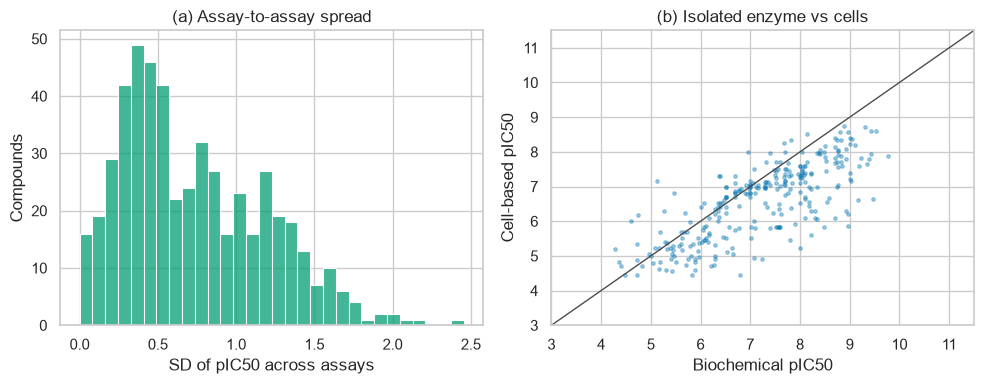

In [7]:
repeated = per_compound.query("variant == 'WT' and assay_kind == 'biochemical' and n_measurements >= 3")
print(
    f"{len(repeated)} compounds have ≥ 3 WT biochemical measurements; "
    f"median within-compound SD = {repeated['pIC50_sd'].median():.2f} log units "
    f"(≈ {10 ** repeated['pIC50_sd'].median():.1f}-fold)"
)

wt = (
    per_compound.query("variant == 'WT'")
    .pivot_table(index="parent_molecule_chembl_id", columns="assay_kind", values="pIC50_median")
    .dropna(subset=["biochemical", "cell-based"])
)
diff = wt["biochemical"] - wt["cell-based"]
print(
    f"{len(wt)} compounds measured both ways; biochemical minus cell-based pIC50: "
    f"median {diff.median():+.2f}, {(diff > 0).mean():.0%} more potent on the isolated enzyme"
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(repeated["pIC50_sd"], bins=30, ax=axes[0], color=sns.color_palette("colorblind")[2])
axes[0].set(xlabel="SD of pIC50 across assays", ylabel="Compounds", title="(a) Assay-to-assay spread")
axes[1].scatter(
    wt["biochemical"], wt["cell-based"], s=6, alpha=0.35, color=sns.color_palette("colorblind")[0]
)
lims = (3, 11.5)
axes[1].plot(lims, lims, color="0.3", lw=1)
axes[1].set(
    xlim=lims,
    ylim=lims,
    xlabel="Biochemical pIC50",
    ylabel="Cell-based pIC50",
    title="(b) Isolated enzyme vs cells",
)
fig.tight_layout()
fig.savefig(FIGURES / "egfr_02_reproducibility.png", dpi=150)

## 5 · Q4 — Do approved drugs show the expected resistance pattern?

Approved EGFR drugs come from ChEMBL's **mechanism-of-action** table (max phase 4, small molecules), so the list isn't
typed by hand. The *generation* labels are background pharmacology knowledge, added for interpretation.

In [8]:
mech = chembl("mechanisms", timeout=240).paginate_items(
    "chembl/api/data/mechanism.json", {"target_chembl_id": TARGET, "limit": 1000}
)
mech = pd.DataFrame(mech)
parents = sorted(mech["parent_molecule_chembl_id"].unique())
mols = pd.DataFrame(
    chembl("molecules", timeout=240).paginate_items(
        "chembl/api/data/molecule.json",
        {
            "molecule_chembl_id__in": ",".join(parents),
            "only": "molecule_chembl_id,pref_name,max_phase,first_approval,molecule_type",
            "limit": 1000,
        },
    )
)
mols["max_phase"] = pd.to_numeric(mols["max_phase"])
approved = mols.query("max_phase == 4 and molecule_type == 'Small molecule'").set_index("molecule_chembl_id")

GENERATION = {  # background knowledge for interpretation
    "GEFITINIB": "1st gen (reversible)",
    "ERLOTINIB": "1st gen (reversible)",
    "LAPATINIB": "1st gen (reversible)",
    "AFATINIB": "2nd gen (covalent, pan-ErbB)",
    "DACOMITINIB": "2nd gen (covalent, pan-ErbB)",
    "NERATINIB": "2nd gen (covalent, pan-ErbB)",
    "OSIMERTINIB": "3rd gen (covalent, T790M-selective)",
    "OLMUTINIB": "3rd gen (covalent, T790M-selective)",
    "LAZERTINIB": "3rd gen (covalent, T790M-selective)",
    "MOBOCERTINIB": "exon 20 insertion",
    "BRIGATINIB": "ALK inhibitor (also EGFR)",
}
approved["pref_name"] = approved["pref_name"].str.split().str[0]  # "DACOMITINIB ANHYDROUS" → "DACOMITINIB"
approved["generation"] = approved["pref_name"].map(GENERATION).fillna("other")
approved[["pref_name", "first_approval", "generation"]].sort_values("first_approval")

,pref_name,first_approval,generation
molecule_chembl_id,,,
CHEMBL939,GEFITINIB,2003.0,1st gen (reversible)
CHEMBL553,ERLOTINIB,2004.0,1st gen (reversible)
CHEMBL554,LAPATINIB,2007.0,1st gen (reversible)
CHEMBL1173655,AFATINIB,2013.0,"2nd gen (covalent, pan-ErbB)"
CHEMBL3353410,OSIMERTINIB,2015.0,"3rd gen (covalent, T790M-selective)"
CHEMBL3786343,OLMUTINIB,2016.0,"3rd gen (covalent, T790M-selective)"
CHEMBL180022,NERATINIB,2017.0,"2nd gen (covalent, pan-ErbB)"
CHEMBL3545311,BRIGATINIB,2017.0,ALK inhibitor (also EGFR)
CHEMBL2110732,DACOMITINIB,2018.0,"2nd gen (covalent, pan-ErbB)"


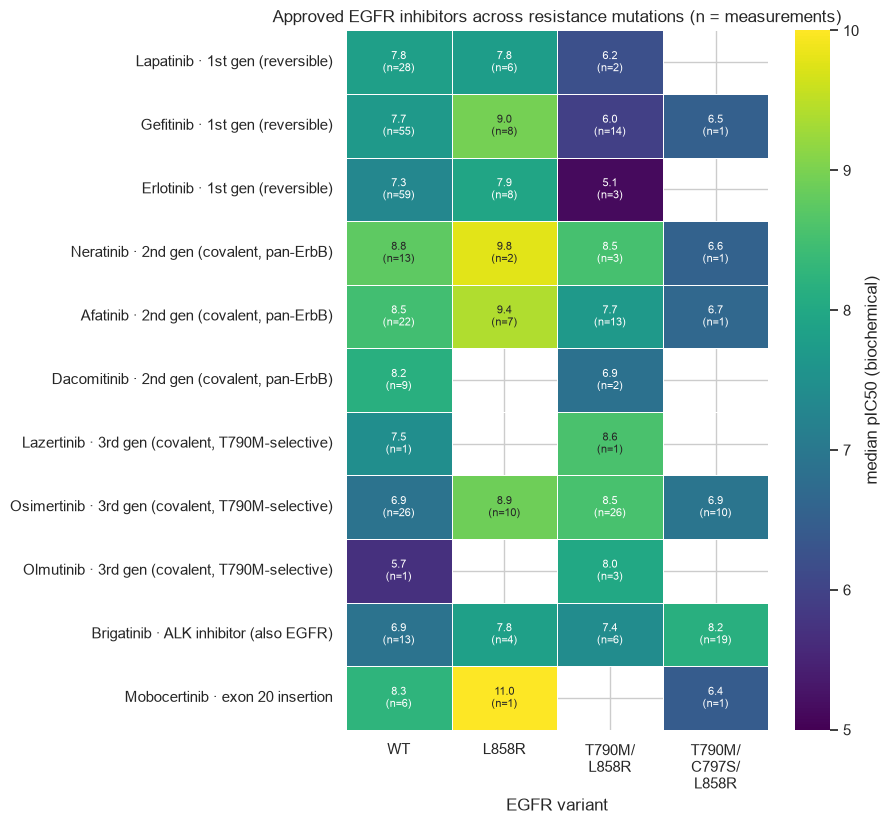

In [9]:
VARIANTS = ["WT", "L858R", "T790M/L858R", "T790M/C797S/L858R"]
drug_bio = per_compound[per_compound["parent_molecule_chembl_id"].isin(approved.index)].query(
    "assay_kind == 'biochemical' and variant in @VARIANTS"
)
heat = drug_bio.pivot_table(index="parent_molecule_chembl_id", columns="variant", values="pIC50_median")
heat = heat.reindex(columns=VARIANTS)
heat.index = [f"{approved.loc[i, 'pref_name'].title()} · {approved.loc[i, 'generation']}" for i in heat.index]
heat = heat.loc[heat.notna().sum(axis=1) >= 2].sort_values(["WT"], ascending=False)
heat = heat.iloc[np.argsort([s.split(" · ")[1] for s in heat.index], kind="stable")]
counts = (
    drug_bio.assign(
        label=lambda d: [
            f"{approved.loc[i, 'pref_name'].title()} · {approved.loc[i, 'generation']}"
            for i in d["parent_molecule_chembl_id"]
        ]
    )
    .pivot_table(index="label", columns="variant", values="n_measurements")
    .reindex(index=heat.index, columns=VARIANTS)
)
annot = heat.round(1).astype(str) + "\n(n=" + counts.fillna(0).astype(int).astype(str) + ")"
annot = annot.where(heat.notna(), "")

fig, ax = plt.subplots(figsize=(9, 0.6 * len(heat) + 1.8))
sns.heatmap(
    heat,
    annot=annot,
    fmt="",
    annot_kws={"fontsize": 8},
    cmap="viridis",
    vmin=5,
    vmax=10,
    linewidths=0.5,
    cbar_kws={"label": "median pIC50 (biochemical)"},
    ax=ax,
)
ax.set_xticklabels([v.replace("/", "/\n") for v in VARIANTS], rotation=0)
ax.set(
    xlabel="EGFR variant",
    ylabel="",
    title="Approved EGFR inhibitors across resistance mutations (n = measurements)",
)
fig.tight_layout()
fig.savefig(FIGURES / "egfr_03_drugs_by_variant.png", dpi=150)

## 6 · Q5 — Which compounds prefer the resistant mutant?

For every compound measured biochemically on both wild-type EGFR and the double mutant **T790M/L858R**:
points **above** the diagonal inhibit the resistant mutant more strongly than wild type. That is the design goal of
third-generation inhibitors, because sparing wild-type EGFR (skin, gut) reduces side effects.

604 compounds measured on both; 35% are ≥ 10× more potent on T790M/L858R, 12% are ≥ 10× more potent on wild type


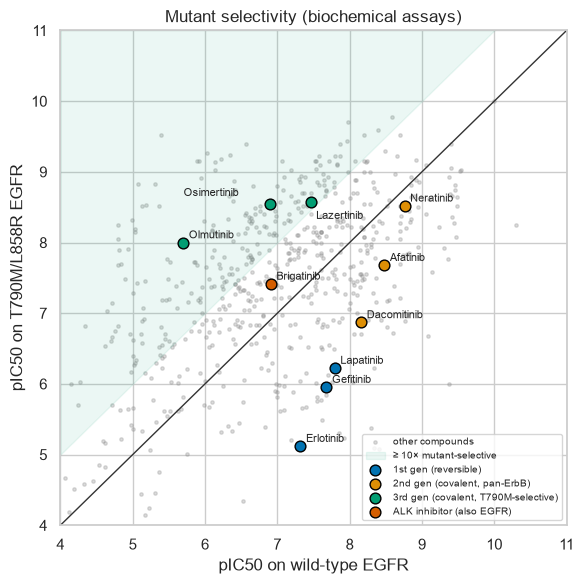

In [10]:
pair = (
    per_compound.query("assay_kind == 'biochemical' and variant in ['WT', 'T790M/L858R']")
    .pivot_table(index="parent_molecule_chembl_id", columns="variant", values="pIC50_median")
    .dropna()
)
pair["selectivity"] = pair["T790M/L858R"] - pair["WT"]  # >0: prefers the mutant
print(
    f"{len(pair):,} compounds measured on both; "
    f"{(pair['selectivity'] >= 1).mean():.0%} are ≥ 10× more potent on T790M/L858R, "
    f"{(pair['selectivity'] <= -1).mean():.0%} are ≥ 10× more potent on wild type"
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(pair["WT"], pair["T790M/L858R"], s=6, alpha=0.3, color="0.55", label="other compounds")
lims = (4, 11)
ax.plot(lims, lims, color="0.2", lw=1)
ax.fill_between(
    lims,
    [lims[0] + 1, lims[1] + 1],
    lims[1] + 2,
    color=sns.color_palette("colorblind")[2],
    alpha=0.08,
    label="≥ 10× mutant-selective",
)
palette = dict(zip(sorted(approved["generation"].unique()), sns.color_palette("colorblind"), strict=False))
OFFSETS = {"OSIMERTINIB": (-62, 6), "LAZERTINIB": (4, -12)}  # avoid overlapping labels
plotted = pair[pair.index.isin(approved.index)]
for cid, row in plotted.iterrows():
    gen, name = approved.loc[cid, "generation"], approved.loc[cid, "pref_name"]
    ax.scatter(row["WT"], row["T790M/L858R"], s=60, color=palette[gen], edgecolor="black", zorder=3)
    ax.annotate(
        name.title(),
        (row["WT"], row["T790M/L858R"]),
        fontsize=8,
        xytext=OFFSETS.get(name, (4, 3)),
        textcoords="offset points",
    )
for gen in sorted(approved.loc[plotted.index, "generation"].unique()):
    ax.scatter([], [], s=60, color=palette[gen], edgecolor="black", label=gen)
ax.set(
    xlim=lims,
    ylim=lims,
    xlabel="pIC50 on wild-type EGFR",
    ylabel="pIC50 on T790M/L858R EGFR",
    title="Mutant selectivity (biochemical assays)",
)
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "egfr_04_mutant_selectivity.png", dpi=150)

## 7 · Q6 — How has published EGFR chemistry changed over time?

`largest_document_share` shows how much of a year comes from a single source document, which is a warning sign when one
large deposited dataset dominates a year.

,measurements,median_pIC50,mutant_share,largest_document_share
year,,,,
2014,745,7.33,0.13,0.46
2015,718,7.19,0.29,0.11
2016,975,7.35,0.22,0.12
2017,1610,7.26,0.26,0.16
2018,916,7.26,0.27,0.20
2019,1026,6.80,0.20,0.12
2020,416,6.90,0.27,0.10
2021,2263,7.80,0.07,0.43
2022,1470,7.19,0.28,0.21


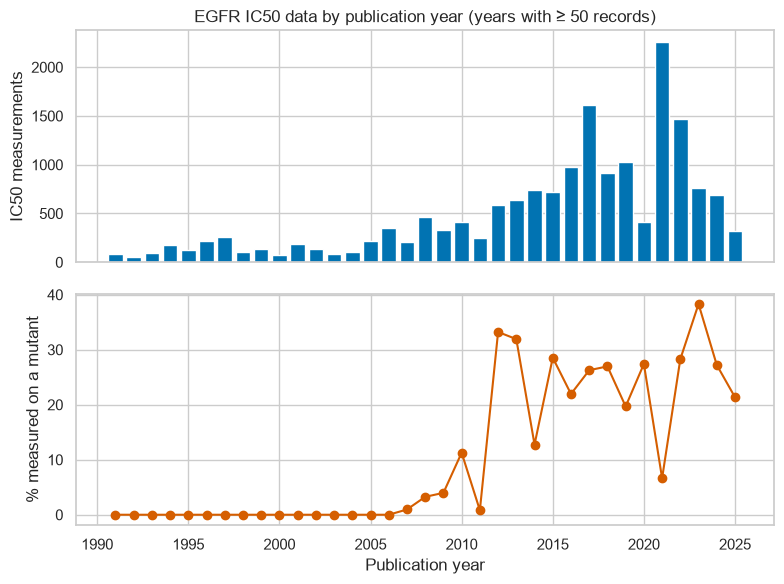

In [11]:
by_year = clean.dropna(subset=["document_year"]).assign(
    mutant=lambda d: ~d["variant"].isin(["WT", "undefined mutant"]),
    year=lambda d: d["document_year"].astype(int),
)
yearly = by_year.groupby("year").agg(
    measurements=("pIC50", "size"),
    median_pIC50=("pIC50", "median"),
    mutant_share=("mutant", "mean"),
    largest_document_share=("document_chembl_id", lambda s: s.value_counts(normalize=True).iloc[0]),
)
yearly = yearly[yearly["measurements"] >= 50]

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].bar(yearly.index, yearly["measurements"], color=sns.color_palette("colorblind")[0])
axes[0].set(ylabel="IC50 measurements", title="EGFR IC50 data by publication year (years with ≥ 50 records)")
axes[1].plot(yearly.index, yearly["mutant_share"] * 100, marker="o", color=sns.color_palette("colorblind")[3])
axes[1].set(ylabel="% measured on a mutant", xlabel="Publication year")
fig.tight_layout()
fig.savefig(FIGURES / "egfr_05_trends.png", dpi=150)
yearly.round(2).tail(12)

## 8 · Findings

All numbers are for ChEMBL release **ChEMBL_37** (19,378 EGFR IC50 records with a pChEMBL value; 10,687 compounds; 1,041 source documents).

**Q1 · Cleaning.** Most of the cleaning happens before the data arrives. ChEMBL only assigns a pChEMBL value to exact (`=`),
unflagged measurements in standard units, so filtering on `pchembl_value` already removed the 7,222 censored or
non-standard IC50 records (26,600 → 19,378), and the exact-value and validity checks then remove nothing. The step that
matters locally is **potential duplicates: 2,106 records (10.9 %)** are values re-reported from an earlier paper. Left in,
they would make well-studied compounds look more certain than they are.

**Q2 · Potency.** Of 9,204 compounds tested biochemically on wild-type EGFR, **49 % have a median IC50 ≤ 100 nM** and 24 %
≤ 10 nM. This reflects *what gets published*, not chemistry in general: inactive compounds are rarely reported, so
ChEMBL is not a source of true negatives for machine-learning models.

**Q3 · Reproducibility.** For the 515 compounds with ≥ 3 independent wild-type biochemical measurements, the median
spread is **0.63 log units (≈ 4-fold)**. Differences smaller than about half a log unit between compounds from different
papers are therefore within noise. The 283 compounds measured both ways are a median **0.5 log units (≈ 3×) more potent
on the isolated enzyme than in cells** (77 % of them), which fits the cellular barriers (high intracellular ATP,
membrane permeability, protein binding).

**Q4 · Approved drugs (figure 3).** The resistance history of EGFR therapy is visible in the data:
* **1st generation** drugs are *more* potent on the activating mutation L858R than on wild type (gefitinib 9.0 vs 7.7),
  the molecular basis of treatment response. They lose potency on **T790M/L858R** (gefitinib 7.7 → 6.0, ≈ 50×,
  n = 14; erlotinib 7.3 → 5.1, n = 3).
* **3rd generation** drugs reverse the pattern: osimertinib is ≈ 40× more potent on T790M/L858R (8.5) than on wild
  type (6.9), with n = 26 measurements each. Adding **C797S** (the residue osimertinib binds covalently) brings it back to
  6.9 (n = 10).
* **2nd generation** covalent drugs inhibit T790M/L858R strongly in vitro (neratinib 8.5, afatinib 7.7) but are just as
  potent on wild type, so they gain no selectivity (clinically, wild-type inhibition limits their dose).
* On the triple mutant **T790M/C797S/L858R**, the most potent approved drug here is **brigatinib (8.2, n = 19)**, an
  ALK inhibitor, not an EGFR-designed drug.
* Caveat: lazertinib, olmutinib and mobocertinib values rest on 1–3 measurements. The heatmap shows n in each cell so
  this is visible.

**Q5 · Mutant selectivity (figure 4).** Of 604 compounds measured on both wild type and T790M/L858R, **35 % are ≥ 10×
mutant-selective** and only 12 % prefer wild type. Post-2010 medicinal chemistry has deliberately targeted the resistant
mutant. The approved drugs separate cleanly by generation along the diagonal.

**Q6 · Trends (figure 5).** No mutant EGFR data exist before 2007. After 2010, typically 20–38 % of each year's
measurements use a mutant. The **2021 peak is an artefact of one source**: a single high-throughput dataset
(CHEMBL5728555, 975 records, median pIC50 8.3) supplies 43 % of that year, which raises the yearly median to 7.8 and
pulls the mutant share down to 7 %. Year-level trends from ChEMBL need a per-document check like this.

**Data-model lessons (worth knowing before reusing ChEMBL):**
* ChEMBL's variant field encodes **point mutations only**. Exon 20 insertions (mobocertinib's indication) are filed as
  `UNDEFINED MUTATION`, with the actual mutation only in the assay text (720 records here).
* **All 683 cell-based records are wild type.** Assays in mutant cell lines (e.g. NCI-H1975) are mapped to the cell-line
  target, not to EGFR CHEMBL203, so this query can't compare mutants in cells.
* `assay_type = "B"` ("binding/biochemical") also covers some cellular phosphorylation assays, so "biochemical" is
  ChEMBL's classification, not a guarantee of a purified-enzyme assay.
* The API failed at deep offsets (> 10,000) and later had a full outage. Year-partitioned queries plus the cache made
  the download resumable, and the notebook's assertion confirms the partitions add up to ChEMBL's total.

## Reproducibility & FAIR notes
* **Source:** ChEMBL web services, target CHEMBL203, `standard_type = IC50`, records with a pChEMBL value; the ChEMBL
  release is recorded in section 1. Raw API responses (with request URL and fetch time) are cached in
  `data/raw/api_cache/chembl/`; the cleaned table is written to `data/processed/chembl_egfr_ic50_clean.csv`. Neither is
  committed (repository data policy).
* **Every filter is explicit and counted** (section 2) and implemented in tested code, not ad-hoc notebook cells.
* **Re-run:** `make lab` → this notebook → *Run All* (EMBL-EBI DS kernel). Delete the cache folder for a newer release.
* **Licence:** ChEMBL data is available under [CC BY-SA 3.0](https://chembl.gitbook.io/chembl-interface-documentation/about#data-licensing).